# Projeto da disciplina de Processamento de imagens

O projeto consiste em software de detecção de raças de cachorros, utilizando processamento de imagens e IA


In [1]:
# Importando bibliotecas necessárias
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
from ultralytics import YOLO
import cv2

In [3]:
# Dataset
dataset = "imagens"

racas = sorted(os.listdir(dataset))

print("Número de raças:", len(racas))

Número de raças: 120


In [4]:
# Contar o número de imagens por raça
contagem_imagens = {}

for raca in racas:
    pasta = os.path.join(dataset, raca)

    imagens = [
        arquivo
        for arquivo in os.listdir(pasta)
        if arquivo.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    contagem_imagens[raca] = len(imagens)

    print(f"Raça: {raca}, Número de imagens: {len(imagens)}")

Raça: n02085620-Chihuahua, Número de imagens: 152
Raça: n02085782-Japanese_spaniel, Número de imagens: 185
Raça: n02085936-Maltese_dog, Número de imagens: 252
Raça: n02086079-Pekinese, Número de imagens: 149
Raça: n02086240-Shih-Tzu, Número de imagens: 214
Raça: n02086646-Blenheim_spaniel, Número de imagens: 188
Raça: n02086910-papillon, Número de imagens: 196
Raça: n02087046-toy_terrier, Número de imagens: 172
Raça: n02087394-Rhodesian_ridgeback, Número de imagens: 172
Raça: n02088094-Afghan_hound, Número de imagens: 239
Raça: n02088238-basset, Número de imagens: 175
Raça: n02088364-beagle, Número de imagens: 195
Raça: n02088466-bloodhound, Número de imagens: 187
Raça: n02088632-bluetick, Número de imagens: 171
Raça: n02089078-black-and-tan_coonhound, Número de imagens: 159
Raça: n02089867-Walker_hound, Número de imagens: 153
Raça: n02089973-English_foxhound, Número de imagens: 157
Raça: n02090379-redbone, Número de imagens: 148
Raça: n02090622-borzoi, Número de imagens: 151
Raça: n02

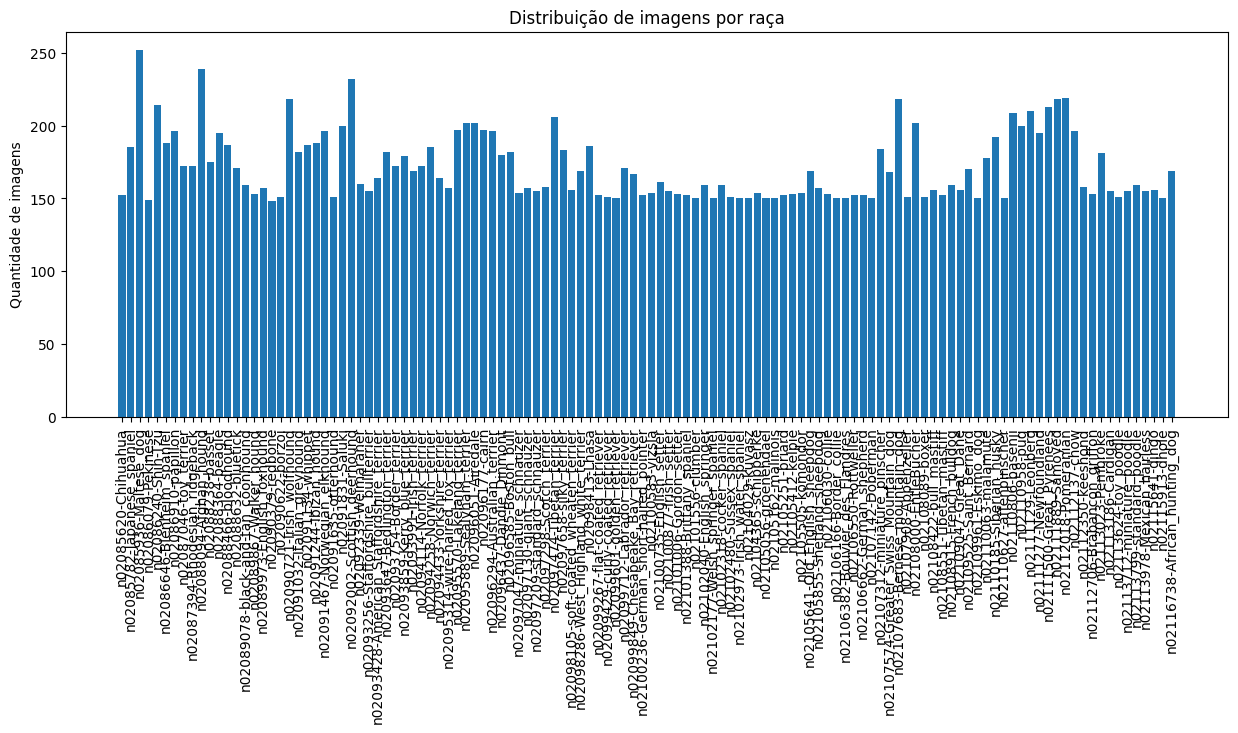

In [5]:
plt.figure(figsize=(15, 5))

plt.bar(
    contagem_imagens.keys(),
    contagem_imagens.values()
)

plt.xticks(rotation=90)
plt.ylabel("Quantidade de imagens")
plt.title("Distribuição de imagens por raça")

plt.show()

In [ ]:
# Tamanho das imagens por raça

dataset_path = r"C:\Users\maria\OneDrive\Documentos\projetoPSRaças\imagens"

dados = []

for raiz, pastas, arquivos in os.walk(dataset_path):

    # Seleciona apenas arquivos de imagem
    imagens = [
        arquivo for arquivo in arquivos
        if arquivo.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Só processa pastas que possuem imagens
    if imagens:

        tamanhos = []
        imagens_invalidas = 0

        for arquivo in imagens:

            caminho = os.path.join(raiz, arquivo)

            try:
                with Image.open(caminho) as imagem:
                    largura, altura = imagem.size
                    tamanhos.append((largura, altura))

            except:
                imagens_invalidas += 1

        if tamanhos:

            larguras = [t[0] for t in tamanhos]
            alturas = [t[1] for t in tamanhos]

            # Nome da pasta que contém as imagens
            raca = os.path.basename(raiz)

            dados.append({
                "Raça": raca,
                "Quantidade de imagens": len(tamanhos),

                "Largura mínima": min(larguras),
                "Largura máxima": max(larguras),
                "Largura média": round(sum(larguras) / len(larguras), 2),

                "Altura mínima": min(alturas),
                "Altura máxima": max(alturas),
                "Altura média": round(sum(alturas) / len(alturas), 2),

                "Imagens inválidas": imagens_invalidas
            })

df = pd.DataFrame(dados)

df = df.sort_values("Raça")

df

df.to_csv("analise_tamanhos_imagens_racas.csv", index=False, encoding="utf-8-sig")

In [2]:
# Contorno dos cachorros nas imagens
# 1. Carregar o modelo YOLOv8 pré-treinado
model = YOLO("yolov8n-seg.pt")  # Modelo pré-treinado

# 2. Pasta com as imagens originais e a pasta que vai ser criada com as imagens recortadas
pasta_entrada = "imagens"
pasta_saida = "imagens_recortadas"

# 3. os.walk vasculha todas as pastas e subpastas dentro da pasta de entrada
for raiz, diretorios, arquivos in os.walk(pasta_entrada):
    for nome_arq in arquivos:
        if nome_arq.lower().endswith(('.png', '.jpg', '.jpeg')):
            caminho_in = os.path.join(raiz, nome_arq)

            # 3.1 Recria a subpasta da raça no diretório de saída
            caminho_relat = os.path.relpath(raiz, pasta_entrada)
            pasta_saida_atual = os.path.join(pasta_saida, caminho_relat)
            os.makedirs(pasta_saida_atual, exist_ok=True)
            caminho_out = os.path.join(pasta_saida_atual, nome_arq)

            # 4. Lê a imagem 
            img = cv2.imread(caminho_in)
            if img is None:
                continue

            # 5. O YOLO faz a deteção do objeto
            results = model(img)

            for result in results:
                if len(result.boxes) > 0:
                    for box in result.boxes:
                        if int(box.cls[0]) == 16:

                            # 6. Extrai as coodernadas da caixa delimitadora
                            x1, y1, x2, y2 = map(int, box.xyxy[0])

                            # 7. Faz o recorte da imagem usando fatiamento (slicing)
                            recorte = img[y1:y2, x1:x2]

                            # 8. Salva a imagem recortada na pasta de saída
                            cv2.imwrite(caminho_out, recorte)

                            break


0: 640x448 1 dog, 137.5ms
Speed: 9.0ms preprocess, 137.5ms inference, 7.2ms postprocess per image at shape (1, 3, 640, 448)

0: 640x512 1 cow, 184.4ms
Speed: 5.8ms preprocess, 184.4ms inference, 3.3ms postprocess per image at shape (1, 3, 640, 512)

0: 384x640 1 person, 1 dog, 141.2ms
Speed: 3.9ms preprocess, 141.2ms inference, 3.9ms postprocess per image at shape (1, 3, 384, 640)

0: 640x448 1 dog, 138.7ms
Speed: 5.5ms preprocess, 138.7ms inference, 3.6ms postprocess per image at shape (1, 3, 640, 448)

0: 640x448 1 dog, 125.8ms
Speed: 2.4ms preprocess, 125.8ms inference, 3.5ms postprocess per image at shape (1, 3, 640, 448)

0: 480x640 1 cat, 176.5ms
Speed: 3.8ms preprocess, 176.5ms inference, 4.1ms postprocess per image at shape (1, 3, 480, 640)

0: 640x640 1 person, 229.0ms
Speed: 6.8ms preprocess, 229.0ms inference, 5.1ms postprocess per image at shape (1, 3, 640, 640)

0: 640x480 1 dog, 1 teddy bear, 352.5ms
Speed: 5.8ms preprocess, 352.5ms inference, 5.6ms postprocess per image